# 02 · Análise exploratória com foco em negócio

**Projeto:** Tech Challenge Fase 1 · Case NPS Preditivo
**Pergunta orientadora:** *quais fatores operacionais realmente explicam a satisfação do cliente e em que ponto da jornada a empresa deveria agir antes da pesquisa de NPS?*

**Como ler este notebook.** Cada seção responde a uma pergunta de negócio. O código está disponível para quem quiser reproduzir, mas toda conclusão vem escrita em linguagem simples logo depois do gráfico, pensando em um(a) gerente de operações que não precisa entender estatística.

---

> ### Resumo executivo
>
> **1. O ponto de partida é crítico.** NPS de **−80**: de cada 100 clientes, 84 são detratores e só 4 são promotores. **9 em cada 10 pedidos chegam atrasados.**
>
> **2. O que mais pesa é a quebra de promessa, não a espera.** O **atraso** é o fator nº 1. O **prazo total** de entrega, por si só, **não muda a nota**: o cliente aceita esperar 14 dias se isso foi o combinado; não aceita esperar 1 dia além do combinado.
>
> **3. Existe ponto de ruptura, e ele chega cedo.** Pedidos no prazo têm NPS −34; com **1 dia** de atraso, −67; a partir de **3 dias**, praticamente **todo cliente vira detrator** (97%) e **nenhum** vira promotor.
>
> **4. O atendimento é o segundo amplificador.** Cada contato extra e cada reclamação derrubam a nota. Com **3 ou mais contatos**, 95% são detratores. Resolver devagar também custa, em menor escala.
>
> **5. Quem o cliente é importa pouco; o que acontece com o pedido importa muito.** Região, idade, tempo de casa, valor do pedido, frete, parcelas e desconto **não** diferenciam a nota. A satisfação é definida pela **jornada**, não pelo **perfil**.
>
> **6. O que gera detratores:** **90%** dos detratores tiveram atraso de 2+ dias **ou** 4+ reclamações. São dois alvos operacionais claros e mensuráveis antes da pesquisa.

In [1]:
# Configuração do ambiente
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from src import config as cfg
from src.metrics import nps_value, nps_summary, nps_bootstrap_ci
from src.viz import set_style, subtitle, save

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
COL = cfg.COLORS
CAT = cfg.CATEGORY_COLORS

# Base tratada gerada no notebook 01 (com flags de qualidade e faixas de negócio)
df = pd.read_csv(cfg.DATA_PROCESSED_PATH)
band_orders = {
    "delay_band": ["No prazo", "1 dia", "2 dias", "3 dias", "4+ dias"],
    "complaints_band": ["0–1", "2–3", "4–5", "6+"],
    "contacts_band": ["0", "1", "2", "3+"],
    "resolution_band": ["0–2 dias", "3–5 dias", "6–8 dias", "9+ dias"],
    "age_band": ["18–25", "26–35", "36–45", "46–55", "56+"],
    "tenure_band": ["Até 1 ano", "1–3 anos", "3–5 anos", "5+ anos"],
    "order_value_band": ["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (maior)"],
    "nps_category": cfg.NPS_CATEGORY_ORDER,
}
for col, order in band_orders.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

key_metrics = {}   # números-chave reaproveitados no relatório e na apresentação
print(f"Pedidos analisados: {len(df):,}")

Pedidos analisados: 2,500


## 1. Panorama: como está a satisfação hoje?

O **NPS** resume a satisfação em um número de −100 a +100: **% de promotores (nota 9–10) menos % de detratores (nota 0–6)**. Neutros (7–8) não entram na conta, mas são clientes “em cima do muro”.

In [2]:
overall_nps = nps_value(df["nps_score"])
ci_low, ci_high = nps_bootstrap_ci(df["nps_score"])
shares = df["nps_category"].value_counts(normalize=True).reindex(cfg.NPS_CATEGORY_ORDER) * 100
late_share = df["is_late"].mean() * 100

key_metrics.update({
    "n_orders": int(len(df)),
    "nps": round(overall_nps, 1), "nps_ci95": [round(ci_low, 1), round(ci_high, 1)],
    "pct_detractors": round(shares["Detrator"], 1), "pct_passives": round(shares["Neutro"], 1),
    "pct_promoters": round(shares["Promotor"], 1),
    "mean_score": round(df["nps_score"].mean(), 2),
    "pct_late": round(late_share, 1),
    "mean_delay_days": round(df["delivery_delay_days"].mean(), 2),
})
print(f"NPS geral: {overall_nps:.0f}  (IC 95%: {ci_low:.0f} a {ci_high:.0f})")
print(f"Nota média: {df['nps_score'].mean():.1f} de 10")
print(f"Pedidos entregues com atraso: {late_share:.0f}%  | atraso médio: {df['delivery_delay_days'].mean():.1f} dias")
shares.round(1).to_frame("% dos clientes")

NPS geral: -80  (IC 95%: -82 a -78)
Nota média: 4.4 de 10
Pedidos entregues com atraso: 89%  | atraso médio: 2.2 dias


,% dos clientes
nps_category,
Detrator,84.4
Neutro,11.2
Promotor,4.4


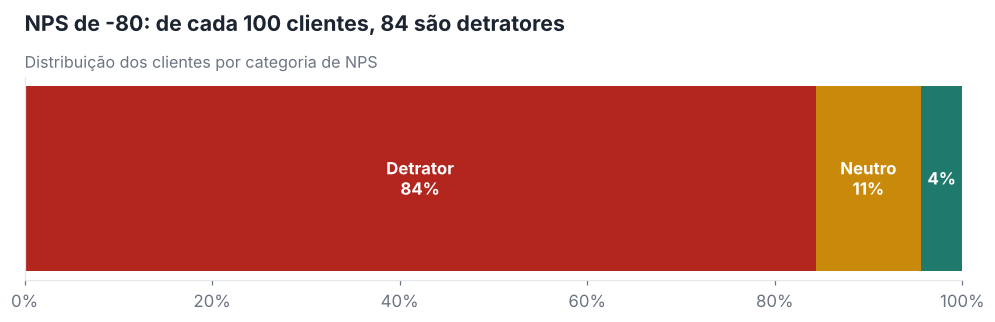

In [3]:
fig, ax = plt.subplots(figsize=(11, 2.4))
left = 0
for cat in cfg.NPS_CATEGORY_ORDER:
    ax.barh(0, shares[cat], left=left, color=CAT[cat], height=0.55)
    label = f"{cat}\n{shares[cat]:.0f}%" if shares[cat] > 8 else f"{shares[cat]:.0f}%"
    ax.text(left + shares[cat] / 2, 0, label, ha="center", va="center",
            color="white", fontweight="bold", fontsize=11)
    left += shares[cat]
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f"NPS de {overall_nps:.0f}: de cada 100 clientes, 84 são detratores")
subtitle(ax, "Distribuição dos clientes por categoria de NPS")
save(fig, "02_panorama_nps")
plt.show()

**O que isso significa para o negócio.** Um NPS de −80 significa que, a cada cliente que recomenda a empresa, há cerca de **19** que podem falar mal dela. Como referência qualitativa, empresas de varejo online bem avaliadas costumam operar com NPS positivo; o patamar atual indica um problema **estrutural**, não pontual. O intervalo de confiança de 95% (−82 a −78) mostra que o número é estável: não é um efeito de amostra pequena.

## 2. Por que isso importa: satisfação vira receita

Antes de procurar as causas, vale mostrar o **custo** da insatisfação. Usamos a recompra em 30 dias apenas como **consequência** (ela acontece depois da pesquisa).

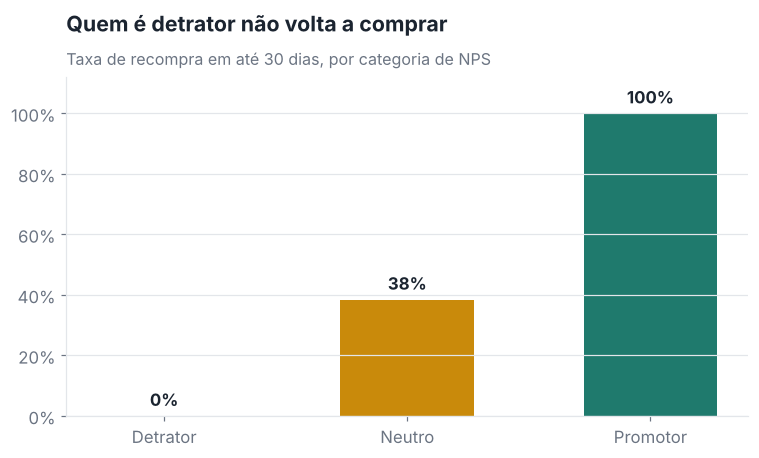

,% que recomprou em 30 dias
nps_category,
Detrator,0.0
Neutro,38.4
Promotor,100.0


In [4]:
repeat = df.groupby("nps_category", observed=True)["repeat_purchase_30d"].mean() * 100
key_metrics["repeat_rate_by_category"] = repeat.round(1).to_dict()
key_metrics["repeat_rate_overall"] = round(df["repeat_purchase_30d"].mean() * 100, 1)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(repeat.index, repeat.values, color=[CAT[c] for c in repeat.index], width=0.55)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in repeat.values], padding=4, fontweight="bold")
ax.set_ylim(0, 112); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Quem é detrator não volta a comprar")
subtitle(ax, "Taxa de recompra em até 30 dias, por categoria de NPS")
save(fig, "03_recompra_por_categoria")
plt.show()
repeat.round(1).to_frame("% que recomprou em 30 dias")

**O que isso significa.** Nenhum detrator recomprou em 30 dias; todos os promotores recompraram. Na prática, cada detrator evitado é um cliente com chance real de voltar.

> ⚠️ **Cuidado com a leitura:** a relação aqui é perfeita demais (0% vs 100%), o que sugere que a base foi gerada com uma regra. Em dados reais, o efeito é forte mas não absoluto. Use este gráfico para mostrar a **direção** do impacto, não para projetar receita.

## 3. Quais fatores parecem mais críticos para a satisfação?

Respondemos de duas formas complementares:

1. **Relação individual:** para cada fator, quanto a nota tende a cair (ou subir) quando ele aumenta (correlação de Spearman, de −1 a +1).
2. **Peso exclusivo de cada fator:** olhando todos os fatores juntos, quanto da variação da nota **deixaríamos de explicar** se ignorássemos aquele fator. Isso separa o efeito de cada um, mesmo quando eles acontecem juntos.

Recompra e CSAT ficam **de fora** (são consequência da satisfação, não causa; ver notebook 01).

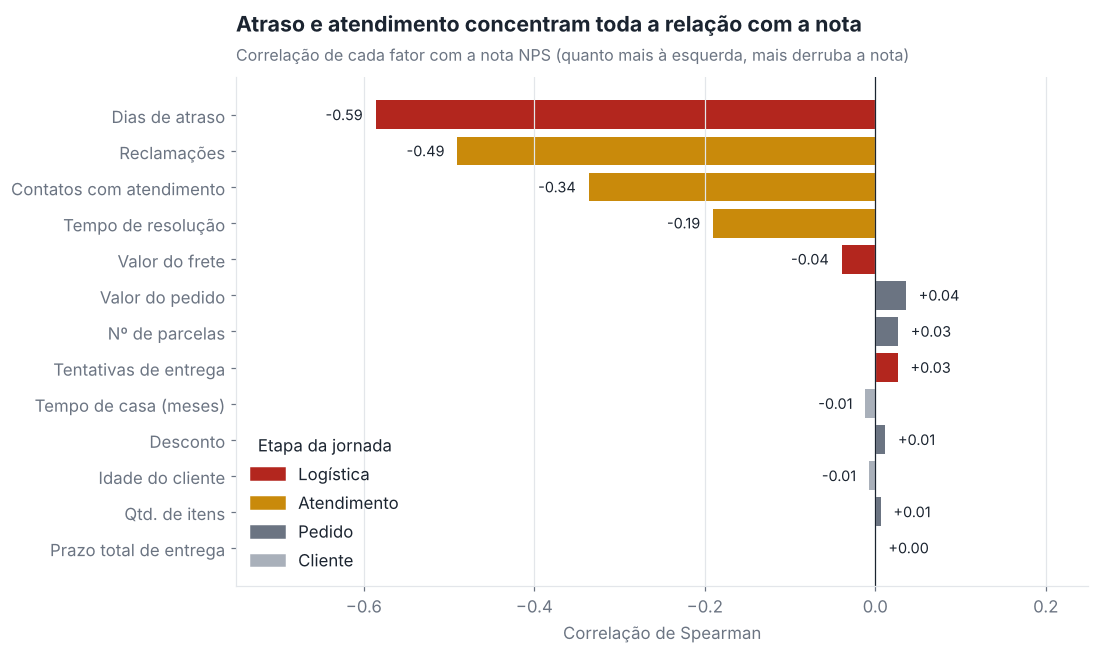

,correlacao,p_valor,etapa,significativo_5%
Dias de atraso,-0.6,0.0,Logística,True
Reclamações,-0.5,0.0,Atendimento,True
Contatos com atendimento,-0.3,0.0,Atendimento,True
Tempo de resolução,-0.2,0.0,Atendimento,True
Valor do frete,-0.0,0.0,Logística,True
Tempo de casa (meses),-0.0,0.6,Cliente,False
Idade do cliente,-0.0,0.7,Cliente,False
Prazo total de entrega,0.0,1.0,Logística,False
Qtd. de itens,0.0,0.8,Pedido,False
Desconto,0.0,0.6,Pedido,False


In [5]:
stage_of = {**{c: "Cliente" for c in cfg.CUSTOMER_COLS}, **{c: "Pedido" for c in cfg.ORDER_COLS},
            **{c: "Logística" for c in cfg.LOGISTICS_COLS}, **{c: "Atendimento" for c in cfg.SERVICE_COLS}}
stage_colors = {"Logística": COL["detractor"], "Atendimento": COL["passive"],
                "Pedido": COL["muted"], "Cliente": "#A9B0BA"}

corr = df[cfg.DRIVER_COLS].corrwith(df["nps_score"], method="spearman")
pvals = pd.Series({c: stats.spearmanr(df[c], df["nps_score"]).pvalue for c in cfg.DRIVER_COLS})
ranking = pd.DataFrame({"correlacao": corr, "p_valor": pvals,
                        "etapa": [stage_of[c] for c in cfg.DRIVER_COLS]})
ranking["significativo_5%"] = ranking["p_valor"] < 0.05
ranking = ranking.reindex(ranking["correlacao"].abs().sort_values().index)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([cfg.LABELS_PT[c] for c in ranking.index], ranking["correlacao"],
        color=[stage_colors[s] for s in ranking["etapa"]])
for i, v in enumerate(ranking["correlacao"]):
    ax.text(v + (-0.015 if v < 0 else 0.015), i, f"{v:+.2f}", va="center",
            ha="right" if v < 0 else "left", fontsize=9.5)
ax.axvline(0, color=COL["ink"], lw=0.8); ax.set_xlim(-0.75, 0.25)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in stage_colors.values()]
ax.legend(handles, stage_colors.keys(), loc="lower left", title="Etapa da jornada")
ax.set_title("Atraso e atendimento concentram toda a relação com a nota")
subtitle(ax, "Correlação de cada fator com a nota NPS (quanto mais à esquerda, mais derruba a nota)")
ax.set_xlabel("Correlação de Spearman")
save(fig, "04_ranking_fatores")
plt.show()
ranking.sort_values("correlacao").rename(index=cfg.LABELS_PT).round(3)

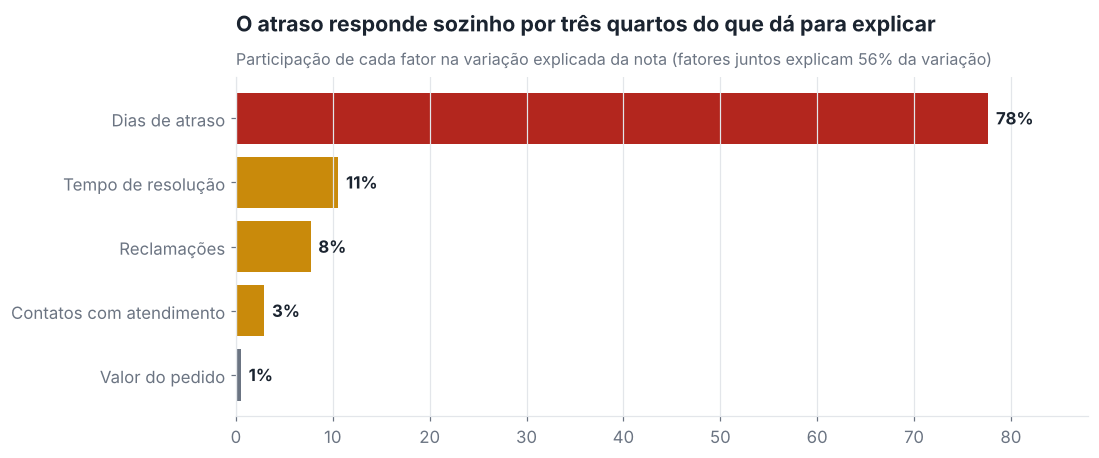

,peso_exclusivo_%,efeito_por_unidade_na_nota
Dias de atraso,77.7,-1.0
Tempo de resolução,10.6,-0.1
Reclamações,7.7,-0.4
Contatos com atendimento,2.9,-0.3
Valor do pedido,0.5,0.0
Valor do frete,0.2,-0.0
Tentativas de entrega,0.2,0.1
Tempo de casa (meses),0.1,-0.0
Nº de parcelas,0.1,0.0
Qtd. de itens,0.0,0.0


In [6]:
# Peso exclusivo de cada fator: queda no R² ao retirar o fator de uma regressão linear
# com todas as variáveis padronizadas. É um modelo EXPLICATIVO (não preditivo), usado
# apenas para separar o efeito de fatores que podem ocorrer juntos.
X = pd.DataFrame(StandardScaler().fit_transform(df[cfg.DRIVER_COLS]), columns=cfg.DRIVER_COLS)
y = df["nps_score"]
full_r2 = LinearRegression().fit(X, y).score(X, y)
unique_contribution = pd.Series({
    c: full_r2 - LinearRegression().fit(X.drop(columns=c), y).score(X.drop(columns=c), y)
    for c in cfg.DRIVER_COLS}).sort_values()
share_of_explained = unique_contribution / unique_contribution.sum() * 100

coefs = pd.Series(LinearRegression().fit(X, y).coef_, index=cfg.DRIVER_COLS)
raw_coefs = pd.Series(LinearRegression().fit(df[cfg.DRIVER_COLS], y).coef_, index=cfg.DRIVER_COLS)

top = share_of_explained[share_of_explained > 0.5]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([cfg.LABELS_PT[c] for c in top.index], top.values,
        color=[stage_colors[stage_of[c]] for c in top.index])
for i, v in enumerate(top.values):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontweight="bold")
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 88)
ax.set_title("O atraso responde sozinho por três quartos do que dá para explicar")
subtitle(ax, f"Participação de cada fator na variação explicada da nota (fatores juntos explicam {full_r2:.0%} da variação)")
save(fig, "05_peso_exclusivo_fatores")
plt.show()

driver_table = pd.DataFrame({
    "peso_exclusivo_%": share_of_explained,
    "efeito_por_unidade_na_nota": raw_coefs,
}).sort_values("peso_exclusivo_%", ascending=False).rename(index=cfg.LABELS_PT)
key_metrics["r2_operational_factors"] = round(full_r2, 3)
key_metrics["driver_share_pct"] = {cfg.LABELS_PT[k]: round(v, 1) for k, v in
                                   share_of_explained.sort_values(ascending=False).items()}
key_metrics["effect_per_unit"] = {cfg.LABELS_PT[k]: round(v, 2) for k, v in raw_coefs.items()}
driver_table.round(2)

**O que isso significa (em linguagem de operação).**

- **Atraso na entrega** é, de longe, o fator mais importante: **cada dia de atraso tira cerca de 1 ponto** da nota (numa escala de 0 a 10), mesmo considerando todos os outros fatores.
- **Reclamações**, **contatos com o atendimento** e **tempo de resolução** vêm a seguir: cada reclamação tira ~0,4 ponto, cada contato ~0,3 ponto, e cada dia esperando uma solução ~0,15 ponto.
- Reclamações e contatos **andam juntos** (quem reclama mais também liga mais), por isso o “peso exclusivo” de cada um parece menor do que é: somados, eles e o tempo de resolução respondem por cerca de **20%** da parte explicada.
- **Todo o resto (valor, frete, desconto, parcelas, itens, idade, tempo de casa, tentativas de entrega) tem efeito praticamente nulo.** O frete aparece como “estatisticamente detectável”, mas o efeito é tão pequeno (correlação de −0,04) que não tem relevância prática.
- Juntos, os fatores operacionais explicam cerca de **56%** da variação da nota. O restante depende de coisas que a base não mede (qualidade do produto, expectativa, comunicação, preço versus concorrência). Isso é alto para dados de comportamento humano, e mostra que **a operação tem nas mãos a maior parte da alavanca**.

## 4. Logística: o cliente aceita esperar, mas não aceita ser surpreendido

Um achado contraintuitivo merece destaque: **o prazo total de entrega não afeta a nota; o atraso, sim.**

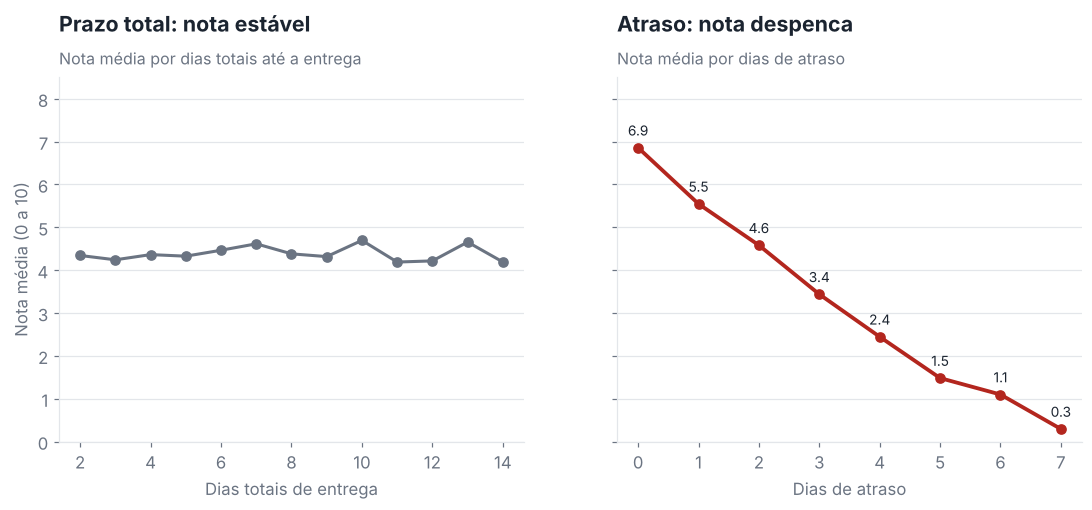

Variação da nota média entre o prazo mais curto e o mais longo: 0.5 ponto
Variação da nota média entre 'no prazo' e 5 dias de atraso: 5.4 pontos


In [7]:
by_time = df.groupby("delivery_time_days")["nps_score"].mean()
by_delay = df.groupby("delivery_delay_days")["nps_score"].agg(["mean", "size"])
by_delay = by_delay[by_delay["size"] >= 10]  # evita conclusões com grupos muito pequenos

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
axes[0].plot(by_time.index, by_time.values, "o-", color=COL["muted"], lw=2)
axes[0].set_title("Prazo total: nota estável")
subtitle(axes[0], "Nota média por dias totais até a entrega")
axes[0].set_xlabel("Dias totais de entrega")
axes[0].set_ylabel("Nota média (0 a 10)")
axes[1].plot(by_delay.index, by_delay["mean"], "o-", color=COL["detractor"], lw=2.5)
for x, v in by_delay["mean"].items():
    axes[1].annotate(f"{v:.1f}", (x, v), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=9)
axes[1].set_title("Atraso: nota despenca")
subtitle(axes[1], "Nota média por dias de atraso")
axes[1].set_xlabel("Dias de atraso")
for ax in axes:
    ax.set_ylim(0, 8.5)
save(fig, "06_prazo_vs_atraso")
plt.show()

time_range = by_time.max() - by_time.min()
key_metrics["score_range_by_delivery_time"] = round(time_range, 2)
print(f"Variação da nota média entre o prazo mais curto e o mais longo: {time_range:.1f} ponto")
print(f"Variação da nota média entre 'no prazo' e 5 dias de atraso: "
      f"{by_delay.loc[0, 'mean'] - by_delay.loc[5, 'mean']:.1f} pontos")

In [8]:
# As outras variáveis logísticas também não diferenciam a nota
other_logistics = pd.concat({
    "Tentativas de entrega": nps_summary(df, "delivery_attempts")[["pedidos", "nota_media", "%_detratores", "NPS"]],
}, names=["fator", "valor"])
other_logistics

pedidos  nota_media  %_detratores   NPS
fator                 valor                                         
Tentativas de entrega 1          824         4.4          84.2 -80.2
                      2          838         4.3          86.8 -83.5
                      3          838         4.5          82.1 -76.1

**O que isso significa.**

- Um pedido que leva **14 dias, mas chega quando prometido**, gera a mesma nota que um que leva 2 dias. O cliente avalia o **cumprimento da promessa**, não a velocidade.
- Isso muda a estratégia: em vez de investir em entregar **mais rápido** (caro), a prioridade é **prometer prazos que a operação consegue cumprir** e **avisar antes** quando algo vai atrasar.
- **Tentativas de entrega e valor do frete não diferenciam a nota** nesta base. É um achado que merece validação (na prática esperaríamos algum efeito de tentativas frustradas), mas os dados não o mostram.

## 5. Existe um “ponto de ruptura” na experiência?

Sim. Agrupando os pedidos por dias de atraso, a proporção de detratores sobe de forma acelerada e há um ponto a partir do qual **não existe mais promotor**.

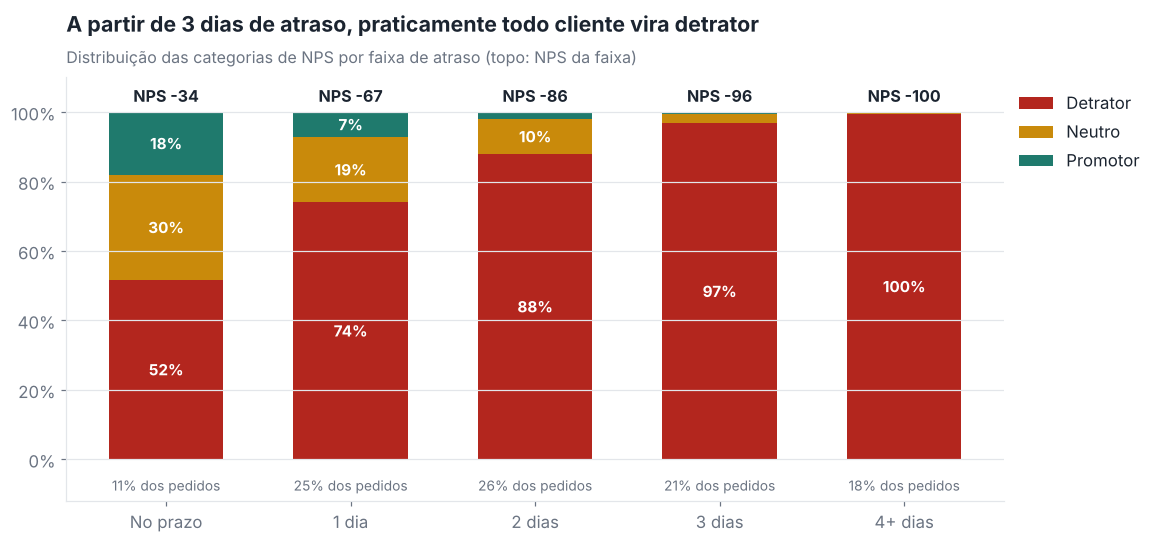

,pedidos,share_base_%,nota_media,%_detratores,%_neutros,%_promotores,NPS,NPS_IC95_inf,NPS_IC95_sup
delay_band,,,,,,,,,
No prazo,277,11.1,6.9,51.6,30.3,18.1,-33.6,-42.2,-24.5
1 dia,615,24.6,5.5,74.0,18.9,7.2,-66.8,-71.7,-62.1
2 dias,646,25.8,4.6,87.9,10.1,2.0,-85.9,-89.0,-82.5
3 dias,525,21.0,3.4,96.8,2.7,0.6,-96.2,-97.7,-94.3
4+ dias,437,17.5,2.0,99.5,0.5,0.0,-99.5,-100.0,-98.9


In [9]:
delay_summary = nps_summary(df, "delay_band", with_ci=True)
key_metrics["delay_summary"] = delay_summary.reset_index().to_dict(orient="records")

pct = (pd.crosstab(df["delay_band"], df["nps_category"], normalize="index") * 100)\
        .reindex(columns=cfg.NPS_CATEGORY_ORDER)
fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(pct))
for cat in cfg.NPS_CATEGORY_ORDER:
    ax.bar(pct.index.astype(str), pct[cat], bottom=bottom, color=CAT[cat], label=cat, width=0.62)
    for i, v in enumerate(pct[cat]):
        if v >= 6:
            ax.text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center", color="white",
                    fontweight="bold", fontsize=10)
    bottom += pct[cat].values
for i, (band, row) in enumerate(delay_summary.iterrows()):
    ax.text(i, 103, f"NPS {row['NPS']:.0f}", ha="center", fontweight="bold",
            color=COL["ink"], fontsize=10.5)
    ax.text(i, -9, f"{row['share_base_%']:.0f}% dos pedidos", ha="center",
            color=COL["muted"], fontsize=9)
ax.set_ylim(-12, 110); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("A partir de 3 dias de atraso, praticamente todo cliente vira detrator")
subtitle(ax, "Distribuição das categorias de NPS por faixa de atraso (topo: NPS da faixa)")
save(fig, "07_ruptura_atraso")
plt.show()
delay_summary

**O que isso significa.**

| Faixa de atraso | O que acontece | Leitura para a operação |
|---|---|---|
| **No prazo** | NPS −34, 18% de promotores | Ainda negativo: entregar no prazo é **necessário, mas não suficiente** |
| **1 dia** | NPS cai para −67: **metade da distância até o fundo** é percorrida no 1º dia | O primeiro dia de atraso é o mais caro; avisar o cliente aqui é decisivo |
| **2 dias** | 88% de detratores | Zona de alerta máximo |
| **3 dias** | **97% de detratores** | **Ponto de ruptura**: a relação está praticamente perdida |
| **4+ dias** | **Zero promotores** | Nenhuma ação posterior recupera a nota nesta base |

Os intervalos de confiança (colunas `NPS_IC95`) não se sobrepõem entre as faixas: as diferenças são reais, não ruído. O ponto de ruptura prático está entre **2 e 3 dias**: é nesse intervalo que a operação precisa ter um gatilho de ação.

## 6. Atendimento: cada contato extra é um sinal de que algo deu errado

Contato com o atendimento raramente é espontâneo: o cliente procura a empresa quando tem um problema. Por isso, o número de contatos funciona como um **termômetro de atrito**.

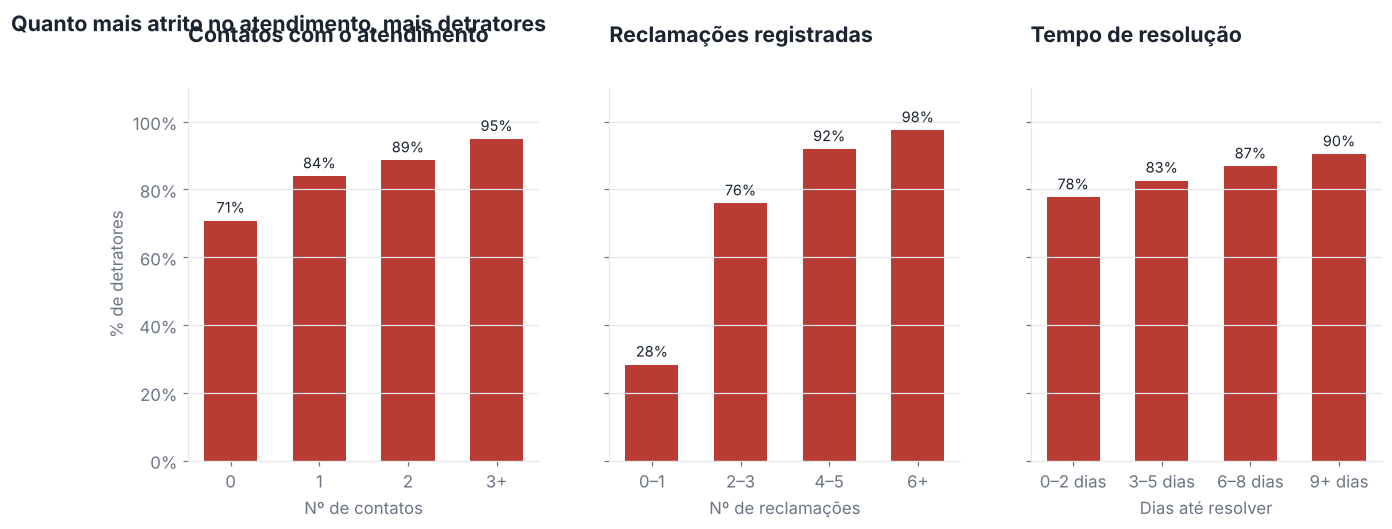

pedidos  share_base_%  nota_media  %_detratores  \
Contatos    0             554          22.2         5.5          70.8   
            1             816          32.6         4.7          83.9   
            2             640          25.6         4.1          88.6   
            3+            490          19.6         2.9          94.9   
Reclamações 0–1           145           5.8         7.9          28.3   
            2–3           784          31.4         5.3          75.9   
            4–5          1044          41.8         4.0          91.9   
            6+            527          21.1         2.8          97.5   
Resolução   0–2 dias      629          25.2         5.0          77.7   
            3–5 dias      619          24.8         4.5          82.6   
            6–8 dias      637          25.5         4.2          86.8   
            9+ dias       615          24.6         3.8          90.4   

                      %_neutros  %_promotores   NPS  NPS_IC95_inf  \
Contatos    0              19.0          10.3 -60.5         -66.1   
            1              11.6           4.4 -79.5         -83.0   
            2               9.2           2.2 -86.4         -89.4   
            3+              4.5           0.6 -94.3         -96.5   
Reclamações 0–1            47.6          24.1  -4.1         -15.9   
            2–3            17.2           6.9 -69.0         -73.0   
            4–5             6.2           1.9 -89.9         -92.0   
            6+              2.3           0.2 -97.3         -98.7   
Resolução   0–2 dias       14.8           7.5 -70.3         -74.9   
            3–5 dias       12.3           5.2 -77.4         -81.4   
            6–8 dias       10.2           3.0 -83.8         -87.1   
            9+ dias         7.6           2.0 -88.5         -91.4   

                      NPS_IC95_sup  
Contatos    0                -54.9  
            1                -76.1  
            2                -83.0  
            3+               -92.0  
Reclamações 0–1                8.3  
            2–3              -64.7  
            4–5              -87.7  
            6+               -95.8  
Resolução   0–2 dias         -65.5  
            3–5 dias         -73.0  
            6–8 dias         -80.2  
            9+ dias          -85.4

In [10]:
contacts_summary = nps_summary(df, "contacts_band", with_ci=True)
complaints_summary = nps_summary(df, "complaints_band", with_ci=True)
resolution_summary = nps_summary(df, "resolution_band", with_ci=True)
key_metrics["contacts_summary"] = contacts_summary.reset_index().to_dict(orient="records")
key_metrics["complaints_summary"] = complaints_summary.reset_index().to_dict(orient="records")
key_metrics["resolution_summary"] = resolution_summary.reset_index().to_dict(orient="records")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (summary, title, xlabel) in zip(axes, [
        (contacts_summary, "Contatos com o atendimento", "Nº de contatos"),
        (complaints_summary, "Reclamações registradas", "Nº de reclamações"),
        (resolution_summary, "Tempo de resolução", "Dias até resolver")]):
    bars = ax.bar(summary.index.astype(str), summary["%_detratores"], color=COL["detractor"],
                  alpha=0.9, width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in summary["%_detratores"]], padding=3, fontsize=9.5)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylim(0, 110)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].set_ylabel("% de detratores")
fig.suptitle("Quanto mais atrito no atendimento, mais detratores", x=0.01, ha="left",
             fontweight="bold", fontsize=14, y=1.04)
save(fig, "08_atendimento")
plt.show()
pd.concat({"Contatos": contacts_summary, "Reclamações": complaints_summary,
           "Resolução": resolution_summary})

**O que isso significa.**

- **Contatos:** quem não precisou falar com a empresa tem 71% de detratores; com **3 ou mais contatos**, são **95%**. Cada vez que o cliente precisa voltar a falar com a empresa, a nota cai.
- **Reclamações:** com até 1 reclamação, a maioria **não** é detratora (28%) e o NPS fica perto de zero (−4). A partir de **2 reclamações**, a maioria já é. A **segunda reclamação** é o ponto de virada do atendimento.
- **Tempo de resolução:** o efeito existe, mas é gradual (de 78% para 90% de detratores entre resolver em até 2 dias e em 9+ dias). Resolver rápido ajuda, porém **evitar que o cliente precise reclamar** ajuda mais.

## 7. Quando os problemas se somam

Atraso e reclamações são relativamente independentes (correlação de 0,19): um não é simplesmente consequência do outro. Por isso vale olhar a combinação.

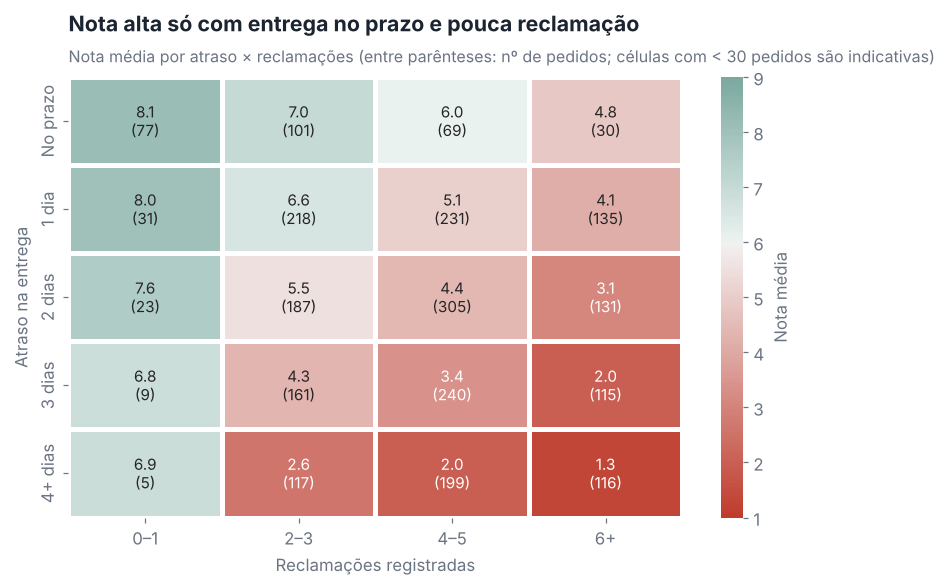

In [11]:
heat = df.pivot_table(index="delay_band", columns="complaints_band", values="nps_score",
                      aggfunc="mean", observed=True)
counts = df.pivot_table(index="delay_band", columns="complaints_band", values="nps_score",
                        aggfunc="size", observed=True)
annot = heat.round(1).astype(str) + "\n(" + counts.astype(str) + ")"
key_metrics["heatmap_delay_complaints"] = {"mean_score": heat.round(1).to_dict(),
                                           "n": counts.to_dict()}

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.heatmap(heat, annot=annot, fmt="", cmap=sns.diverging_palette(15, 170, s=80, l=45, as_cmap=True),
            center=6, vmin=1, vmax=9, linewidths=2, linecolor="white", cbar_kws={"label": "Nota média"},
            ax=ax, annot_kws={"fontsize": 10})
ax.set_xlabel("Reclamações registradas"); ax.set_ylabel("Atraso na entrega")
ax.set_title("Nota alta só com entrega no prazo e pouca reclamação")
subtitle(ax, "Nota média por atraso × reclamações (entre parênteses: nº de pedidos; células com < 30 pedidos são indicativas)")
ax.grid(False)
save(fig, "09_atraso_x_reclamacoes")
plt.show()

**O que isso significa.**

- **Melhor cenário** (sem atraso e até 1 reclamação): nota média **8,1**. Esse é o “padrão-ouro” da experiência e só **3%** dos pedidos o atingem hoje.
- **Pior cenário** (4+ dias de atraso e 6+ reclamações): nota média **1,3**.
- Os efeitos **se somam**: um pedido sem atraso mas com 6+ reclamações (4,8) fica no mesmo patamar de um pedido com 2 dias de atraso e 4–5 reclamações (4,4). As duas frentes (logística e atendimento) precisam andar juntas.

## 8. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Testamos se o **perfil** do cliente ou do pedido diferencia a nota: região, faixa de idade, tempo de casa e faixa de valor do pedido. Usamos o teste de Kruskal-Wallis: um p-valor alto (> 0,05) indica que as diferenças entre os grupos **podem ser apenas acaso**.

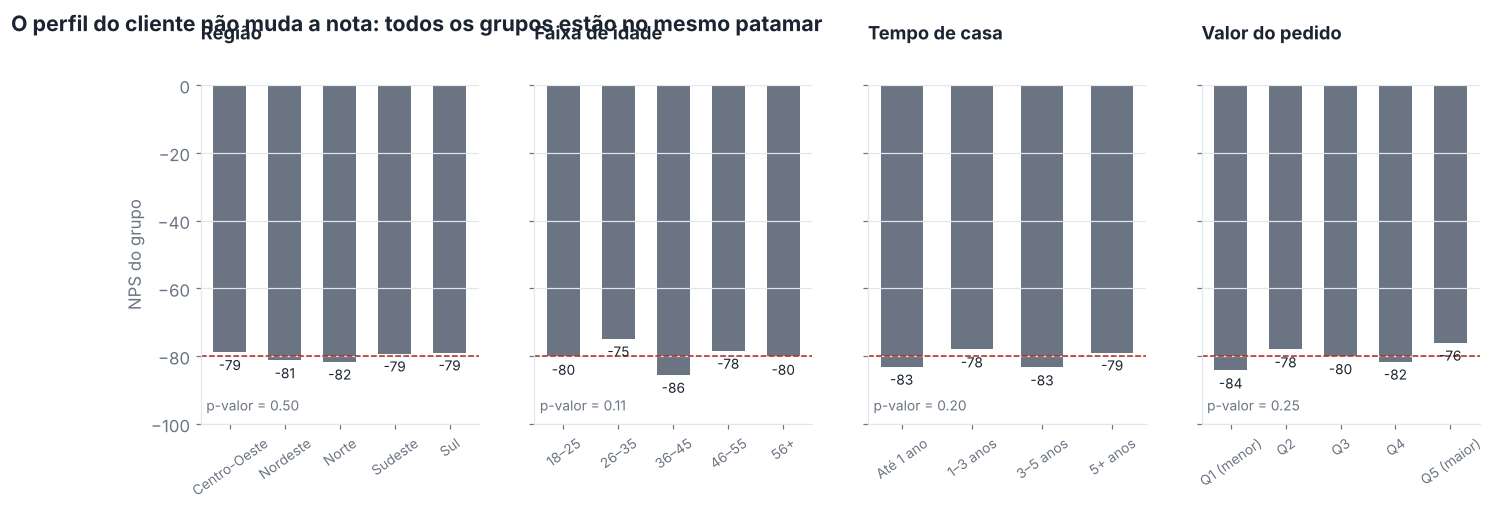

,p_valor,nps_min,nps_max
Região,0.5,-81.6,-78.8
Faixa de idade,0.1,-85.5,-74.8
Tempo de casa,0.2,-83.3,-78.0
Valor do pedido,0.3,-84.2,-76.0


In [12]:
profile_vars = {"customer_region": "Região", "age_band": "Faixa de idade",
                "tenure_band": "Tempo de casa", "order_value_band": "Valor do pedido"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
profile_tests = {}
for ax, (col, label) in zip(axes, profile_vars.items()):
    s = nps_summary(df, col)
    groups = [g["nps_score"].values for _, g in df.groupby(col, observed=True)]
    p = stats.kruskal(*groups).pvalue
    profile_tests[label] = {"p_valor": round(p, 3), "nps_min": s["NPS"].min(), "nps_max": s["NPS"].max()}
    ax.bar(s.index.astype(str), s["NPS"], color=COL["muted"], width=0.6)
    ax.bar_label(ax.containers[0], labels=[f"{v:.0f}" for v in s["NPS"]], padding=3, fontsize=9)
    ax.axhline(overall_nps, color=COL["detractor"], ls="--", lw=1)
    ax.set_title(label, fontsize=12); ax.tick_params(axis="x", rotation=35, labelsize=9)
    ax.text(0.02, 0.04, f"p-valor = {p:.2f}", transform=ax.transAxes, fontsize=9, color=COL["muted"])
    ax.set_ylim(-100, 0)
axes[0].set_ylabel("NPS do grupo")
fig.suptitle("O perfil do cliente não muda a nota: todos os grupos estão no mesmo patamar",
             x=0.01, ha="left", fontweight="bold", fontsize=14, y=1.05)
save(fig, "10_perfil_cliente")
plt.show()
key_metrics["profile_tests"] = profile_tests
pd.DataFrame(profile_tests).T

**O que isso significa.**

- **Nenhum perfil demográfico ou comercial diferencia a satisfação** de forma estatisticamente confiável. Clientes do Sul e do Norte, jovens e seniores, novos e antigos, de ticket alto e baixo: todos estão em torno de NPS −80.
- A diferença entre clientes **satisfeitos e insatisfeitos** está no **que aconteceu com o pedido deles**. O “tipo de cliente” que dá nota alta é o cliente que **recebeu no prazo e não precisou reclamar**; o que dá nota baixa é o que **esperou além do prometido e teve de procurar o atendimento várias vezes**.
- Implicação prática: segmentar ações por região ou idade **não** resolveria o problema. As ações devem ser segmentadas por **situação do pedido**.

In [13]:
# Perfil médio de cada categoria: a "foto" do promotor versus a do detrator
profile_compare = df.groupby("nps_category", observed=True)[
    ["delivery_delay_days", "complaints_count", "customer_service_contacts",
     "resolution_time_days", "delivery_time_days", "order_value", "customer_age",
     "customer_tenure_months"]].mean().T.rename(index=cfg.LABELS_PT)
key_metrics["profile_by_category"] = profile_compare.round(2).to_dict()
profile_compare

nps_category,Detrator,Neutro,Promotor
Dias de atraso,2.4,1.1,0.7
Reclamações,4.4,2.7,2.3
Contatos com atendimento,1.6,1.0,0.7
Tempo de resolução,5.7,4.6,3.7
Prazo total de entrega,8.0,8.3,7.9
Valor do pedido,429.3,458.2,468.1
Idade do cliente,43.4,43.3,43.6
Tempo de casa (meses),61.4,59.8,63.0


**Retrato falado.** O **promotor típico** teve 0,7 dia de atraso, 2,3 reclamações e 0,7 contato. O **detrator típico** teve 2,4 dias de atraso (3×), 4,4 reclamações (2×) e 1,6 contato (2×). Idade, tempo de casa, valor do pedido e prazo total são praticamente iguais entre os grupos.

## 9. O que mais gera detratores?

Olhando apenas para os detratores, qual o peso de cada situação?

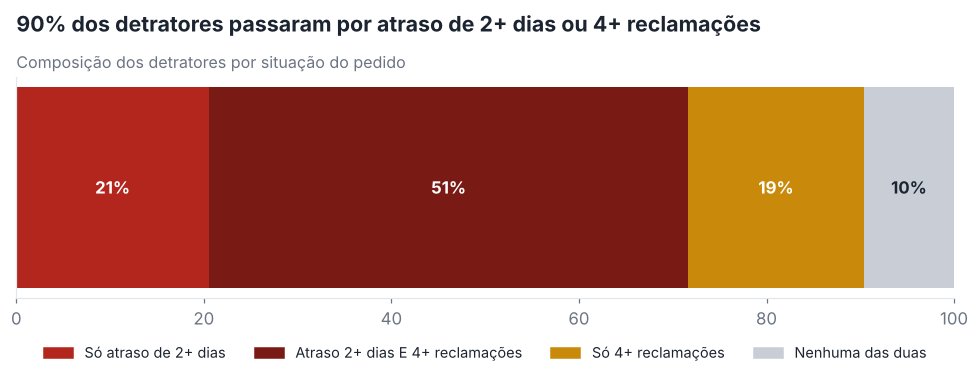

,% dos detratores
Só atraso de 2+ dias,20.5
Atraso 2+ dias E 4+ reclamações,51.1
Só 4+ reclamações,18.7
Nenhuma das duas,9.6


In [14]:
det = df[df["nps_category"] == "Detrator"]
cond_delay = det["delivery_delay_days"] >= 2
cond_complaints = det["complaints_count"] >= 4
composition = pd.Series({
    "Só atraso de 2+ dias": (cond_delay & ~cond_complaints).mean() * 100,
    "Atraso 2+ dias E 4+ reclamações": (cond_delay & cond_complaints).mean() * 100,
    "Só 4+ reclamações": (~cond_delay & cond_complaints).mean() * 100,
    "Nenhuma das duas": (~cond_delay & ~cond_complaints).mean() * 100,
})
key_metrics["detractor_composition"] = composition.round(1).to_dict()
key_metrics["pct_detractors_explained_by_two_triggers"] = round((cond_delay | cond_complaints).mean() * 100, 1)

fig, ax = plt.subplots(figsize=(11, 2.6))
colors = [COL["detractor"], "#7A1A14", COL["passive"], "#C9CED6"]
left = 0
for (label, v), c in zip(composition.items(), colors):
    ax.barh(0, v, left=left, color=c, height=0.55)
    ax.text(left + v / 2, 0, f"{v:.0f}%", ha="center", va="center", color="white" if c != "#C9CED6" else COL["ink"],
            fontweight="bold")
    left += v
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors], composition.index,
          ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=9.5)
ax.set_title(f"{(cond_delay | cond_complaints).mean():.0%} dos detratores passaram por atraso de 2+ dias ou 4+ reclamações")
subtitle(ax, "Composição dos detratores por situação do pedido")
save(fig, "11_composicao_detratores")
plt.show()
composition.round(1).to_frame("% dos detratores")

**O que isso significa.** Dois gatilhos objetivos, que a operação **já mede antes da pesquisa**, cobrem **9 em cada 10 detratores**:

1. **Atraso de 2 dias ou mais** (72% dos detratores).
2. **4 reclamações ou mais** (70% dos detratores).

São candidatos naturais a **alertas operacionais**: quando um pedido cruza qualquer um deles, a empresa sabe, com alta chance, que tem um detrator em formação, e ainda pode agir.

## 10. Ordem de grandeza: quanto o NPS poderia melhorar?

Para ajudar a priorizar, simulamos cenários usando o comportamento **já observado** na base: para cada pedido, aplicamos a chance de ser promotor/detrator observada em pedidos **parecidos** (mesma faixa de reclamações), mas com o atraso do cenário.

> ⚠️ É uma **estimativa de ordem de grandeza**, baseada em associação, não em experimento. Ela supõe que reduzir o atraso traria o cliente para o comportamento observado em pedidos com menos atraso. Mantivemos as reclamações constantes, o que torna o cenário **conservador** (na prática, menos atraso tende a gerar menos reclamação).

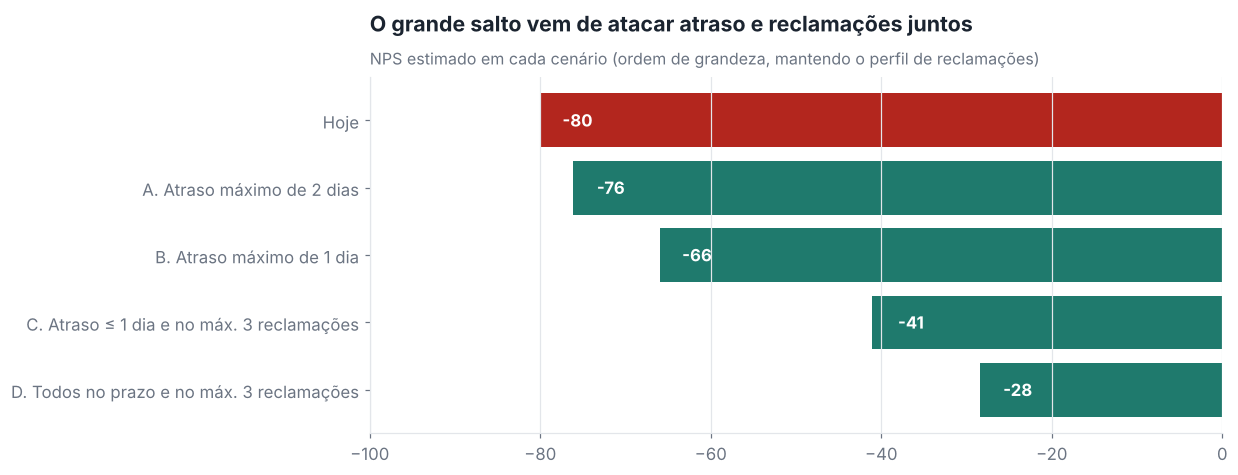

,NPS estimado
Hoje,-80.0
A. Atraso máximo de 2 dias,-76.2
B. Atraso máximo de 1 dia,-66.0
C. Atraso ≤ 1 dia e no máx. 3 reclamações,-41.1
D. Todos no prazo e no máx. 3 reclamações,-28.4


In [15]:
# Probabilidade de promotor e detrator em cada combinação (faixa de atraso x faixa de reclamações)
cell_probs = df.groupby(["delay_band", "complaints_band"], observed=True).agg(
    p_promoter=("is_promoter", "mean"), p_detractor=("is_detractor", "mean"), n=("nps_score", "size"))

def simulate(data, max_delay_band):
    order = band_orders["delay_band"]
    cap = order.index(max_delay_band)
    new_band = data["delay_band"].astype(str).map(lambda b: order[min(order.index(b), cap)])
    keys = list(zip(new_band, data["complaints_band"].astype(str)))
    probs = cell_probs.reset_index().astype({"delay_band": str, "complaints_band": str})\
                      .set_index(["delay_band", "complaints_band"])
    p = probs.loc[keys]
    return (p["p_promoter"].mean() - p["p_detractor"].mean()) * 100

def simulate_both(data, max_delay_band, max_complaints_band):
    order_d, order_c = band_orders["delay_band"], band_orders["complaints_band"]
    cap_d, cap_c = order_d.index(max_delay_band), order_c.index(max_complaints_band)
    nd = data["delay_band"].astype(str).map(lambda b: order_d[min(order_d.index(b), cap_d)])
    nc = data["complaints_band"].astype(str).map(lambda b: order_c[min(order_c.index(b), cap_c)])
    probs = cell_probs.reset_index().astype({"delay_band": str, "complaints_band": str})\
                      .set_index(["delay_band", "complaints_band"])
    p = probs.loc[list(zip(nd, nc))]
    return (p["p_promoter"].mean() - p["p_detractor"].mean()) * 100

scenarios = pd.Series({
    "Hoje": overall_nps,
    "A. Atraso máximo de 2 dias": simulate(df, "2 dias"),
    "B. Atraso máximo de 1 dia": simulate(df, "1 dia"),
    "C. Atraso ≤ 1 dia e no máx. 3 reclamações": simulate_both(df, "1 dia", "2–3"),
    "D. Todos no prazo e no máx. 3 reclamações": simulate_both(df, "No prazo", "2–3"),
})
key_metrics["scenarios_nps"] = scenarios.round(1).to_dict()

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(scenarios.index[::-1], scenarios.values[::-1],
               color=[COL["promoter"]] * 4 + [COL["detractor"]])
ax.bar_label(bars, labels=[f"{v:.0f}" for v in scenarios.values[::-1]], padding=-34,
             color="white", fontweight="bold")
ax.set_xlim(-100, 0); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("O grande salto vem de atacar atraso e reclamações juntos")
subtitle(ax, "NPS estimado em cada cenário (ordem de grandeza, mantendo o perfil de reclamações)")
save(fig, "12_cenarios")
plt.show()
scenarios.round(1).to_frame("NPS estimado")

**O que isso significa.**

- **Limitar o atraso a 2 dias** melhora pouco (cerca de **+4 pontos**): 2 dias de atraso já é zona de detração. Não basta “cortar a cauda”.
- **Limitar o atraso a 1 dia** traz cerca de **+14 pontos**.
- Combinar **atraso de no máximo 1 dia com no máximo 3 reclamações** (atendimento resolvendo antes de o cliente escalar) leva a cerca de **+39 pontos**; com **todos os pedidos no prazo**, cerca de **+52 pontos**.
- O ganho **não é linear**: as duas frentes se reforçam, por isso o plano precisa atacar logística e atendimento **ao mesmo tempo**.
- Mesmo no melhor cenário, o NPS **continua negativo**. Logística e atendimento são as maiores alavancas **dentro desta base**, mas não as únicas: produto, preço e comunicação (que a base não mede) precisam entrar no diagnóstico.

## 11. Respostas às perguntas do desafio

| Pergunta | Resposta |
|---|---|
| **Quais fatores parecem mais críticos para a satisfação?** | **Atraso na entrega** (fator nº 1, ~1 ponto a menos na nota por dia), seguido de **reclamações**, **contatos com o atendimento** e **tempo de resolução**. Valor, frete, desconto, parcelas e prazo total não diferenciam a nota. |
| **O que mais gera detratores?** | **Atraso de 2+ dias** ou **4+ reclamações**: juntos cobrem **90%** dos detratores. |
| **Existe um ponto de ruptura?** | Sim. O **1º dia de atraso** já leva metade da queda (NPS de −34 para −67). Com **3 dias**, 97% viram detratores; com **4+**, não há promotores. No atendimento, a virada acontece na **2ª reclamação** e no **3º contato**. |
| **Que tipo de cliente tem NPS mais alto ou mais baixo?** | O perfil (região, idade, tempo de casa, ticket) **não** diferencia. NPS alto: pedido **no prazo**, **≤ 1 reclamação**, **sem contato** com o SAC (nota média 8,1). NPS baixo: **3+ dias de atraso** e **várias reclamações** (nota média até 1,3). |

### Recomendações (detalhadas no relatório executivo)
1. **Prometer o que dá para cumprir:** recalibrar o prazo exibido no checkout com margem de segurança por rota/transportadora.
2. **Avisar antes do cliente perguntar:** comunicação proativa no 1º dia de atraso, com nova data e canal direto.
3. **Torre de controle de pedidos em risco:** alertas automáticos com gatilhos objetivos (atraso ≥ 1 dia, 2ª reclamação, 2º contato) e fila prioritária.
4. **Resolver na primeira vez:** meta de resolução no 1º contato e autonomia de compensação para a linha de frente.
5. **Medir durante a jornada:** acompanhar semanalmente os gatilhos acima como indicadores antecedentes do NPS.

In [16]:
# Exporta os números-chave para o relatório e a apresentação (fonte única de verdade)
def to_serializable(obj):
    if isinstance(obj, dict):
        return {str(k): to_serializable(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [to_serializable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else round(float(obj), 3)
    return obj

cfg.METRICS_JSON_PATH.write_text(json.dumps(to_serializable(key_metrics), ensure_ascii=False, indent=2),
                                 encoding="utf-8")
print(f"Métricas exportadas para {cfg.METRICS_JSON_PATH.relative_to(cfg.ROOT_DIR)}")

Métricas exportadas para reports/key_metrics.json
